# Experiment results figures

Figures of the experimental evaluation, read from the benchmark log `logs/paper/<RUN>/raw.jsonl`
(10% complexity jitter). The main comparison is AS-MF, QoS-EPD, BA-EPD, BA-EPD+SOH and DARO;
The ablation variants of DARO (`logs/paper/benchmark_ablation_daro`, same seeds; incl. full info) are in the ablation figures, and the Oracle is not shown. If
`logs/paper/benchmark_sensing` exists (same seeds), its extra-sensor variants are merged into the ablation.

| Output (`figures/pdf/`) | Content |
|---|---|
| `exp_overall.pdf` | cost $-R$ per scenario family, 95% CI |
| `exp_tradeoff.pdf` | (a) time vs. energy, (b) QoS vs. reserve violation |
| `exp_aging.pdf` | degradation family: (a) cost, (b) reserve violation vs. SOH |
| `exp_longterm.pdf` | (a) $\Delta$SOH vs. mission time ($w_D$ sweep), (b) km to EOL |
| `exp_ablation.pdf` | paired change in cost vs. DARO per removed component (w/o degradation cost = Lag-RLS) |
| `exp_ablation_soh.pdf` | DARO and its ablation variants under aging (degradation family) |

## Setup

In [103]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

REPO = Path.cwd().resolve()
while not (REPO / 'envs').is_dir() and REPO != REPO.parent:   # notebook lives in <repo>/figures
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from evaluation.lifetime import missions_to_eol  # noqa: E402

RUN = 'benchmark_td3'                     # benchmark run in logs/paper/

RAW = REPO / 'logs' / 'paper' / RUN / 'raw.jsonl'
RAW_SENSING = REPO / 'logs' / 'paper' / 'benchmark_sensing' / 'raw.jsonl'
RAW_ABL = REPO / 'logs' / 'paper' / 'benchmark_ablation_daro' / 'raw.jsonl'   # ablations on DARO
OUT = REPO / 'figures' / 'pdf'
FS = 15

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'font.size': 16, 'axes.titlesize': 16, 'axes.labelsize': 16,
    'xtick.labelsize': 16, 'ytick.labelsize': 16, 'legend.fontsize': 16,
    'axes.grid': True, 'grid.linestyle': '--', 'grid.linewidth': 0.4, 'grid.color': '#c8c8c8',
    'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})

DA = 'DA-Lag-RLS (w=16000)'
FAMILIES = [('tight', 'Tight'), ('switch', 'Switch'),
            ('mismatch', 'Mismatch'), ('combined', 'Combined'),
            ('degradation', 'Degradation'), ('all', 'All')]
# same colours as the trace figures
STYLE = {
    'AS-MF':               dict(color='#9a9a9a', ls=':', marker='X', label='AS-MF'),
    'QoS-EPD':             dict(color='#8c6bb1', ls='-.', marker='v', label='QoS-EPD'),
    'BA-EPD':              dict(color='#e08a2c', ls='--', marker='s', label='BA-EPD'),
    'BA-EPD+SOH':          dict(color='#c8413b', ls='--', marker='D', label='BA-EPD+SOH'),
    'Lag-RLS':             dict(color='#2a5ea8', ls='-', marker='o', label='w/o degradation cost'),   # = DARO with w_D = 0
    DA:                    dict(color='#1a8a4a', ls='-', marker='^', label='DARO'),
    'Lag-RLS (full info)': dict(color='#555555', ls=(0, (1, 1)), marker='P', label='Lag-RLS (full info)'),
    # ablations on DARO (exp_ablation, exp_ablation_soh); w/o degradation cost = Lag-RLS
    'DARO w/o RLS':         dict(color='#d4a017', ls='--', marker='s', label='w/o RLS'),
    'DARO w/o CD':          dict(color='#8c564b', ls='-.', marker='D', label='w/o change detection'),
    'DARO w/o lambda':      dict(color='#e377c2', ls=':', marker='v', label=r'w/o $\lambda$ (mode switching)'),
    'DARO tier select':     dict(color='#17becf', ls=(0, (3, 1, 1, 1)), marker='P', label=r'tier selection of $\lambda$'),
    'DARO w/o QoS cost':    dict(color='#6b6b9a', ls=(0, (5, 2)), marker='X', label='w/o expected QoS cost'),
    'Oracle':              dict(color='#222222', ls=(0, (5, 2)), marker='*', label='Oracle'),
}
MAIN = ['AS-MF', 'QoS-EPD', 'BA-EPD', 'BA-EPD+SOH', DA]

## Helpers

In [104]:
def load():
    rows = [json.loads(line) for line in RAW.read_text().splitlines()]
    for extra in (RAW_SENSING, RAW_ABL):
        if extra.exists():
            rows += [json.loads(line) for line in extra.read_text().splitlines()]
    rows = [r for r in rows if r['family'] != 'nominal']   # nominal family removed from the suite
    for r in rows:   # family renamed: tight_mismatch -> combined
        r['family'] = {'tight_mismatch': 'combined'}.get(r['family'], r['family'])
    by = {}
    for r in rows:
        by.setdefault(r['policy'], []).append(r)
    return by


def boot_ci(x, n=2000, seed=0):
    x = np.asarray(x, float)
    m = x[np.random.default_rng(seed).integers(0, len(x), (n, len(x)))].mean(1)
    return np.percentile(m, 2.5), np.percentile(m, 97.5)


def sel(rs, fam):
    return [r for r in rs if fam == 'all' or r['family'] == fam]


def mean(rs, k):
    return float(np.nanmean([r[k] for r in rs]))


def save(fig, name):
    p = OUT / f'{name}.pdf'
    fig.savefig(p, bbox_inches='tight', pad_inches=0.02)
    print(p.relative_to(REPO))
    plt.show()


by = load()
print({n: len(rs) for n, rs in by.items()})

{'AS-MF': 1590, 'QoS-EPD': 1590, 'BA-EPD': 1590, 'BA-EPD+SOH': 1590, 'Lag-RLS': 1590, 'DA-Lag-RLS (w=1000)': 1590, 'DA-Lag-RLS (w=4000)': 1590, 'DA-Lag-RLS (w=16000)': 1590, 'Lag-RLS w/o SOH est': 1590, 'Lag-RLS w/o lambda': 1590, 'Lag-RLS tier select': 1590, 'Lag-RLS w/o RLS': 1590, 'Lag-RLS w/o probe': 1590, 'Lag-RLS w/o eta': 1590, 'Lag-RLS w/o probe+eta': 1590, 'Lag-RLS w/o CD': 1590, 'Lag-RLS w/o QoS cost': 1590, 'BA-EPD (full info)': 1590, 'Lag-RLS (full info)': 1590, 'Oracle-obs': 1590, 'Oracle': 1590, 'Lag-RLS split power': 1590, 'Lag-RLS event count': 1590, 'Lag-RLS split+events': 1590, 'DARO w/o SOH est': 1590, 'DARO w/o lambda': 1590, 'DARO tier select': 1590, 'DARO w/o RLS': 1590, 'DARO w/o probe': 1590, 'DARO w/o eta': 1590, 'DARO w/o probe+eta': 1590, 'DARO w/o CD': 1590, 'DARO w/o QoS cost': 1590, 'DARO split power': 1590, 'DARO event count': 1590, 'DARO split+events': 1590, 'DARO (full info)': 1590}


## Overall performance (`exp_overall.pdf`)

Cost $-R$ per scenario family; bars above `Y_MAX` (AS-MF) are clipped and labelled with their value.

DA-Lag-RLS (w=16000) [0.51768163 0.32566078 0.53571629 0.57812543 0.26261893 0.50666092] [np.float64(0.06021191125189429), np.float64(0.021301805331230828), np.float64(0.08636334257293576), np.float64(0.039257084357475214), np.float64(0.019976882346678826), np.float64(0.02552086974682327)] [np.float64(0.061218633218461216), np.float64(0.02234666601420837), np.float64(0.08585576382747251), np.float64(0.03485528291533335), np.float64(0.021714260715384404), np.float64(0.02628950392623941)]
figures/pdf/exp_overall.pdf


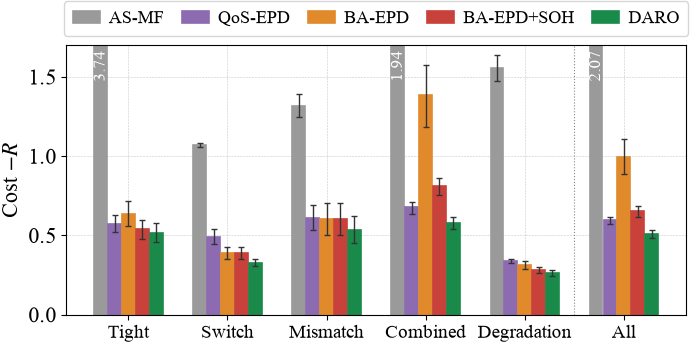

In [105]:
def fig_overall(by):
    """Cost = -return per family; bars above Y_MAX (AS-MF) are clipped and labelled."""
    Y_MAX = 1.7
    fig, ax = plt.subplots(figsize=(8, 3.5))
    nf, nm = len(FAMILIES), len(MAIN)
    w = 0.7 / nm
    for j, n in enumerate(MAIN):
        st = STYLE[n]
        y, lo, hi = [], [], []
        for fam, _ in FAMILIES:
            x = [-r['return'] for r in sel(by[n], fam)]
            a, b = boot_ci(x)
            y.append(np.mean(x)); lo.append(np.mean(x) - a); hi.append(b - np.mean(x))
        xs = np.arange(nf) + (j - (nm - 1) / 2) * w
        ref = n == 'Oracle'
        ax.bar(xs, y, w * 0.92, color='white' if ref else st['color'], ec=st['color'],
               hatch='///' if ref else None, lw=1.2, label=st['label'], zorder=2)
        y = np.array(y)
        clip = y > Y_MAX
        ax.errorbar(xs[~clip], y[~clip], yerr=[np.array(lo)[~clip], np.array(hi)[~clip]],
                    fmt='none', ecolor='#333333', lw=1, capsize=2, zorder=3)
        for x0, y0 in zip(xs[clip], y[clip]):
            ax.text(x0, Y_MAX * 0.98, f'{y0:.2f}', rotation=90, ha='center', va='top',
                    fontsize=FS - 3, color='white', zorder=4)

    print(n, y, lo, hi)
    ax.axvline(nf - 1.5, color='#888888', lw=0.8, ls=':')
    ax.set_xticks(np.arange(nf))
    ax.set_xticklabels([lab for _, lab in FAMILIES], fontsize=FS - 1)
    ax.set_ylabel(r'Cost $-R$')
    ax.set_ylim(0, Y_MAX)
    # ax.grid(axis='y', alpha=0.3, zorder=0)
    ax.legend(ncol=nm, loc='lower center', bbox_to_anchor=(0.5, 1.0), frameon=True,
              handlelength=1.5, columnspacing=1.0, fontsize=FS - 2, handletextpad=0.5, borderpad=0.5)
    save(fig, 'exp_overall')


fig_overall(by)

## Short-term trade-offs (`exp_tradeoff.pdf`)

(a) Mission time vs. load energy; (b) QoS violation vs. reserve violation. Means over all missions.

figures/pdf/exp_tradeoff.pdf


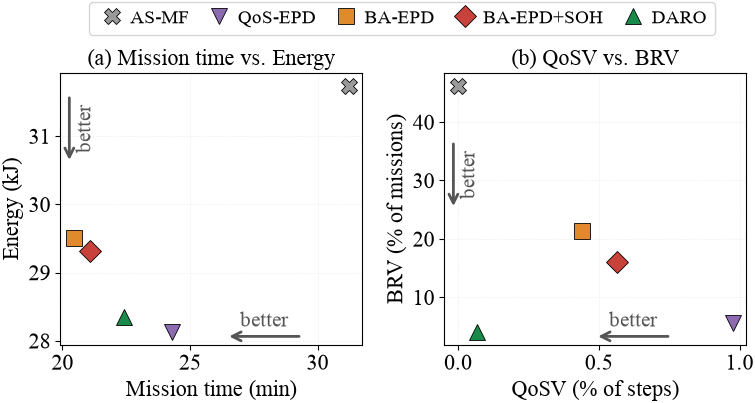

In [106]:
def fig_tradeoff(by):
    names = MAIN
    sty = STYLE
    fig, (a, b) = plt.subplots(1, 2, figsize=(8, 4))
    for n in names:
        rs, st = by[n], sty[n]
        kw = dict(color=st['color'], marker=st['marker'], ms=11,
                  mec='black', mew=0.6, ls='none', label=st['label'], zorder=3)
        a.plot(mean(rs, 'mission_time_s') / 60, mean(rs, 'energy_kj'), **kw)
        b.plot(mean(rs, 'qos_viol_pct'), 100 * mean(rs, 'reserve_viol'), **kw)
    a.set_xlabel('Mission time (min)')
    a.set_ylabel('Energy (kJ)')
    a.set_title('(a) Mission time vs. Energy')
    b.set_xlabel('QoSV (% of steps)')
    b.set_ylabel('BRV (% of missions)')
    b.set_title('(b) QoSV vs. BRV')
    # "better" arrows along the x- and y-axis (lower is better in both), inside the axes on
    # a stretch without data points: (x_start, x_end) along the bottom, (y_start, y_end) along the left
    arrow = dict(arrowstyle='->', color='#555555', lw=2)
    spans = {a: ((0.8, 0.55), (0.92, 0.67)), b: ((0.75, 0.5), (0.75, 0.5))}
    for ax, ((xs, xe), (ys, ye)) in spans.items():
        ax.grid(alpha=0.3)
        ax.annotate('', xy=(xe, 0.03), xytext=(xs, 0.03), xycoords='axes fraction', arrowprops=arrow)
        ax.text((xs + xe) / 2, 0.05, 'better', transform=ax.transAxes, fontsize=FS,
                ha='center', va='bottom', color='#555555')
        ax.annotate('', xy=(0.03, ye), xytext=(0.03, ys), xycoords='axes fraction', arrowprops=arrow)
        ax.text(0.05, (ys + ye) / 2, 'better', transform=ax.transAxes, fontsize=FS,
                ha='left', va='center', rotation=90, color='#555555')
    h, l = a.get_legend_handles_labels()
    fig.legend(h, l, ncol=len(names), loc='lower center', bbox_to_anchor=(0.53, 0.95),
               frameon=True, handletextpad=0.2, columnspacing=0.8, fontsize=FS - 1, handlelength=1.5)
    fig.tight_layout()
    save(fig, 'exp_tradeoff')


fig_tradeoff(by)

## Effect of aging (`exp_aging.pdf`, `exp_ablation_soh.pdf`)

Degradation family: cost and reserve violation vs. SOH. The same function draws the main comparison and the battery-state ablation.

figures/pdf/exp_aging.pdf


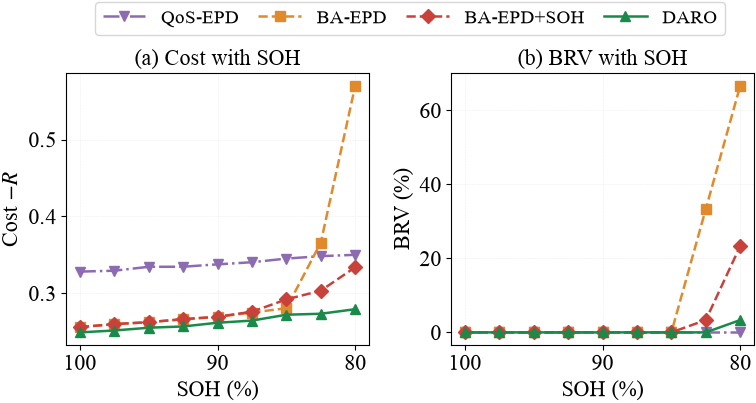

figures/pdf/exp_ablation_soh.pdf


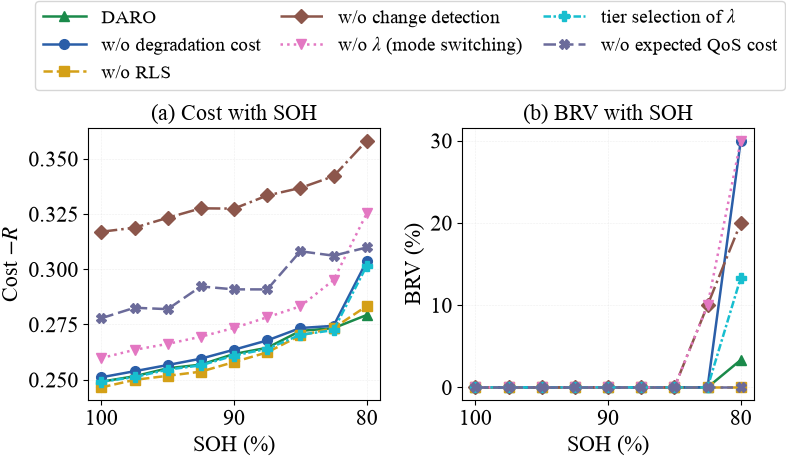

In [107]:
MAIN_AGING = ['QoS-EPD', 'BA-EPD', 'BA-EPD+SOH', DA]   # AS-MF: cost 1.1-2.9, off the scale
# same variants as exp_ablation: DARO, w/o degradation cost (= Lag-RLS), and the main components
ABL_AGING = [DA, 'Lag-RLS', 'DARO w/o RLS', 'DARO w/o CD', 'DARO w/o lambda',
             'DARO tier select', 'DARO w/o QoS cost']


def fig_aging(by, names=MAIN_AGING, name='exp_aging', ncol=4):
    fig, (a, b) = plt.subplots(1, 2, figsize=(8, 4))
    for n in names:
        d = [r for r in by[n] if r['family'] == 'degradation']
        sohs = sorted({r['tags']['soh'] for r in d}, reverse=True)
        at = lambda s: [r for r in d if abs(r['tags']['soh'] - s) < 1e-6]
        cost = [-mean(at(s), 'return') for s in sohs]
        res = [100 * mean(at(s), 'reserve_viol') for s in sohs]
        st = STYLE[n]
        kw = dict(color=st['color'], ls=st['ls'], marker=st['marker'], lw=1.8, ms=7,
                  label=st['label'])
        a.plot(100 * np.array(sohs), cost, **kw)
        b.plot(100 * np.array(sohs), res, **kw)
    a.set_ylabel(r'Cost $-R$')
    a.set_title('(a) Cost with SOH')
    b.set_ylabel('BRV (%)')
    b.set_title('(b) BRV with SOH')
    for ax in (a, b):
        ax.set_xlabel('SOH (%)')
        ax.invert_xaxis()
        ax.grid(alpha=0.3)
    h, l = a.get_legend_handles_labels()
    fig.legend(h, l, ncol=ncol, loc='lower center', bbox_to_anchor=(0.54, 0.95), frameon=True,
               handlelength=2.2, columnspacing=1.0, fontsize=FS - 1)
    fig.tight_layout()
    save(fig, name)


fig_aging(by, ncol=4)
fig_aging(by, ABL_AGING, 'exp_ablation_soh', ncol=3)

## Long-term battery cost (`exp_longterm.pdf`)

(a) Capacity loss vs. mission time for the $w_D$ sweep; (b) distance to end of life relative to BA-EPD.

figures/pdf/exp_longterm.pdf


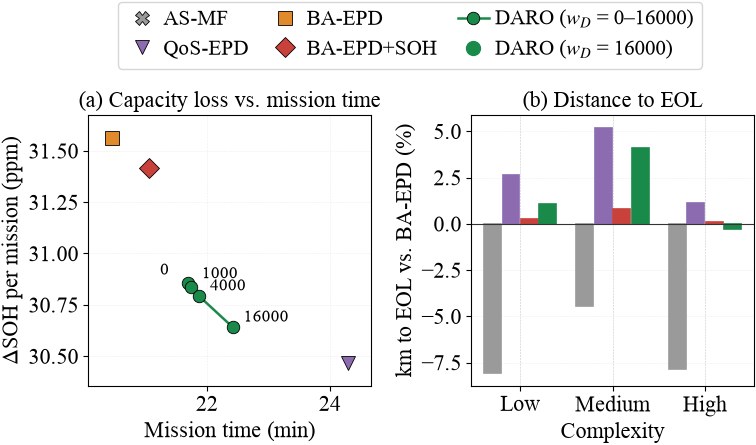

In [108]:
def km_to_eol(rs):
    d = [r for r in rs if r['family'] == 'degradation']
    out = []
    for c in (1.0, 2.0, 3.0):
        lv = sorted({r['tags']['soh'] for r in d if r['tags']['c'] == c}, reverse=True)
        fd = [np.mean([r['fd_cycle'] for r in d if r['tags']['c'] == c
                       and abs(r['tags']['soh'] - s) < 1e-6]) for s in lv]
        out.append(missions_to_eol(lv, fd) * 5.0)
    return np.array(out)


def fig_longterm(by):
    fig, (a, b) = plt.subplots(1, 2, figsize=(8, 4))
    # (a) w_D sweep: Lag-RLS = w_D 0
    sweep = [('Lag-RLS', 0), ('DA-Lag-RLS (w=1000)', 1000), ('DA-Lag-RLS (w=4000)', 4000), (DA, 16000)]
    t = [mean(by[n], 'mission_time_s') / 60 for n, _ in sweep]
    s = [mean(by[n], 'delta_soh_ppm') for n, _ in sweep]
    a.plot(t, s, '-', color=STYLE[DA]['color'], lw=1.8, zorder=2)
    offs = {0: (-20, 6), 1000: (8, 6), 4000: (8, 4), 16000: (8, 4)}
    for (n, w), x, y in zip(sweep, t, s):
        a.plot(x, y, 'o', color=STYLE[DA]['color'], mec='black', mew=0.6, ms=9, zorder=3)
        a.annotate(f'{w}', (x, y), xytext=offs[w], textcoords='offset points', fontsize=FS - 3)
    for n in ['QoS-EPD', 'BA-EPD', 'BA-EPD+SOH']:   # AS-MF (29.9 min, 32.7 ppm) off the scale
        st = STYLE[n]
        a.plot(mean(by[n], 'mission_time_s') / 60, mean(by[n], 'delta_soh_ppm'), st['marker'],
               color=st['color'], mec='black', mew=0.6, ms=10,
               label=st['label'], zorder=3)
    a.set_xlabel('Mission time (min)')
    a.set_ylabel(r'$\Delta$SOH per mission (ppm)')
    a.set_title(r'(a) Capacity loss vs. mission time')
    a.grid(alpha=0.3)
    a.margins(0.1)                       # keep the extreme markers (BA-EPD, QoS-EPD) inside the axes
    # (b) km to EOL, relative to BA-EPD
    names = ['AS-MF', 'QoS-EPD', 'BA-EPD+SOH', DA]
    base = km_to_eol(by['BA-EPD'])
    w = 0.8 / len(names)
    for j, n in enumerate(names):
        st = STYLE[n]
        y = 100 * (km_to_eol(by[n]) / base - 1)
        xs = np.arange(3) + (j - (len(names) - 1) / 2) * w
        b.bar(xs, y, w * 0.92, color=st['color'], ec=st['color'], lw=1.2, label=st['label'],
              zorder=2)
    b.axhline(0, color='#333333', lw=0.8)
    b.set_xticks(range(3))
    b.set_xticklabels(['Low', 'Medium', 'High'])
    b.set_xlabel('Complexity')
    b.set_ylabel('km to EOL vs. BA-EPD (%)')
    b.set_title('(b) Distance to EOL')
    b.grid(axis='y', alpha=0.3, zorder=0)
    # one legend for (a) and (b) on top: same colour per method (markers in (a), bars in (b));
    # DARO is the w_D sweep in (a) and w_D = 16000 in (b)
    order = ['AS-MF', 'QoS-EPD', 'BA-EPD', 'BA-EPD+SOH']
    h = [Line2D([], [], ls='none', marker=STYLE[n]['marker'], color=STYLE[n]['color'], mec='black',
                mew=0.6, ms=10, label=STYLE[n]['label']) for n in order]
    h.append(Line2D([], [], ls='-', marker='o', color=STYLE[DA]['color'], mec='black', mew=0.6,
                    ms=9, lw=1.8, label=r'DARO ($w_D$ = 0–16000)'))      # sweep in (a)
    h.append(Line2D([], [], ls='none', marker='o', color=STYLE[DA]['color'], mec=STYLE[DA]['color'],
                    ms=10, label=r'DARO ($w_D$ = 16000)'))           # bars in (b)
    fig.tight_layout()
    fig.legend(handles=h, ncol=3, loc='lower center', bbox_to_anchor=(0.54, 0.97),
               frameon=True, handletextpad=0.3, columnspacing=1.0, fontsize=FS, handlelength=1.5)
    save(fig, 'exp_longterm')


fig_longterm(by)

## Ablation (`exp_ablation.pdf`)

Paired increase in cost vs. DARO per removed or replaced main component; w/o degradation cost = Lag-RLS ($w_D = 0$).

figures/pdf/exp_ablation.pdf


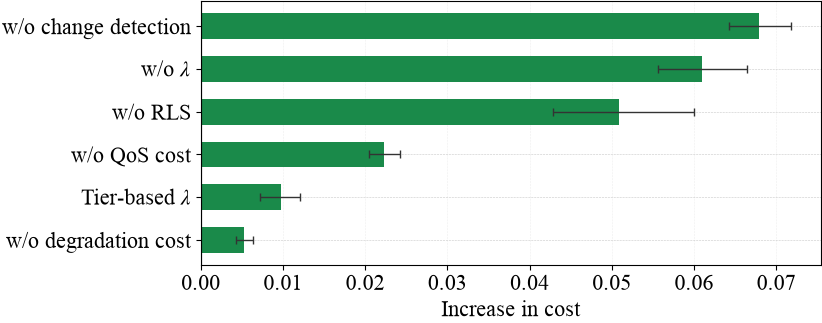

In [ ]:
def fig_ablation(by):
    """Main components removed from / replaced in DARO (sorted), paired vs. DARO.
    w/o degradation cost = Lag-RLS (w_D = 0; the w_D sweep is in exp_longterm); SOH
    estimation, probing, the loss factor and the extra sensors are only given in the text."""
    comp = [('DARO w/o CD', 'w/o change detection'), ('DARO w/o RLS', r'w/o RLS'),
            ('DARO w/o lambda', r'w/o $\lambda$'),
            ('DARO w/o QoS cost', 'w/o QoS cost'),
            ('DARO tier select', r'Tier-based $\lambda$'),
            ('Lag-RLS', 'w/o degradation cost')]
    key = lambda r: (r['scenario'], r['seed_i'])
    ref = {key(r): r['return'] for r in by[DA]}

    def vals(lst):
        out = []
        for n, lab in lst:
            if n not in by:
                continue
            d = [-(r['return'] - ref[key(r)]) for r in by[n]]      # increase in cost
            lo, hi = boot_ci(d)
            out.append((lab, np.mean(d), lo, hi))
        return out

    rows = sorted(vals(comp), key=lambda v: -v[1])
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(rows) + 0.9))
    y = -np.arange(len(rows), dtype=float)
    m = np.array([v[1] for v in rows])
    ax.barh(y, m, 0.6, color=STYLE[DA]['color'], zorder=2)
    ax.errorbar(m, y, xerr=[m - [v[2] for v in rows], [v[3] for v in rows] - m], fmt='none',
                ecolor='#333333', lw=1, capsize=3, zorder=3)
    ax.axvline(0, color='#333333', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([v[0] for v in rows])
    ax.set_xlabel('Cost Increase ($\Delta(-R)$)')
    ax.grid(axis='x', alpha=0.3, zorder=0)
    save(fig, 'exp_ablation')


fig_ablation(by)